## Pre-lab Questions

**(a) A 7 kHz tone is sampled at 10 kHz. What frequency appears?**

Given:

- Original frequency, F = 7 kHz
- Sampling frequency, fs = 10 kHz

Formula:

F_alias = |F - k × fs|

Taking k = 1:

F_alias = |7 - 10|

F_alias = **3 kHz**

Therefore, the frequency that appears after sampling is **3 kHz** due to aliasing.

**(b) Compute Δ and the theoretical SQNR for an 8-bit quantizer with a ±1 V range.**

Given:

- Number of bits, B = 8
- Maximum amplitude, Xm = 1 V

**Step 1: Calculate Delta (Δ)**

Formula:

Δ = 2Xm / 2^B

Δ = (2 × 1) / 2^8

Δ = 2 / 256

Δ = **0.0078125 V**

**Step 2: Calculate theoretical SQNR**

Formula:

SQNR = 6.02B + 1.76

SQNR = (6.02 × 8) + 1.76

SQNR = 48.16 + 1.76

SQNR = **49.92 dB**

Therefore, the quantization step size is **0.0078125 V**, and the theoretical SQNR is **49.92 dB**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
f0 = 7.0
fs = 10.0

t = np.linspace(0, 1, 2000)
n = np.arange(0, int(fs) + 1)
tn = n / fs

In [3]:
f_alias = abs(f0 - fs * round(f0 / fs))

print("Original frequency:", f0, "Hz")
print("Sampling frequency:", fs, "Hz")
print("Alias frequency:", f_alias, "Hz")

Original frequency: 7.0 Hz
Sampling frequency: 10.0 Hz
Alias frequency: 3.0 Hz


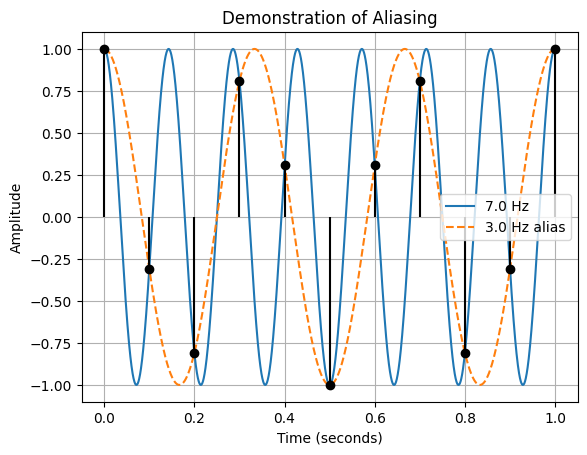

In [4]:
plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias")

plt.stem(tn, np.cos(2*np.pi*f0*tn),
         linefmt="k-", markerfmt="ko", basefmt=" ")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Demonstration of Aliasing")
plt.legend()
plt.grid()
plt.show()

In [5]:
sampling_rates = [12, 14, 20]

for fs_test in sampling_rates:
    f_alias_test = abs(f0 - fs_test * round(f0 / fs_test))

    print("Sampling frequency:", fs_test, "Hz")
    print("Alias frequency:", f_alias_test, "Hz")
    print("--------------------------")

Sampling frequency: 12 Hz
Alias frequency: 5.0 Hz
--------------------------
Sampling frequency: 14 Hz
Alias frequency: 7.0 Hz
--------------------------
Sampling frequency: 20 Hz
Alias frequency: 7.0 Hz
--------------------------


### Task 2.1: Aliasing Results

The original signal frequency was 7 Hz. Different sampling frequencies were tested to observe aliasing.

| Original Frequency (Hz) | Sampling Frequency (Hz) | Alias Frequency (Hz) |
|---:|---:|---:|
| 7 | 10 | 3 |
| 7 | 12 | 5 |
| 7 | 14 | 7 |
| 7 | 20 | 7 |

**Observation:**

When the sampling frequency is 10 Hz, the 7 Hz signal appears as a 3 Hz signal due to aliasing. At a sampling frequency of 20 Hz, the Nyquist frequency is 10 Hz, which is greater than the original signal frequency of 7 Hz. Therefore, the signal can be sampled without aliasing.

In [6]:
from scipy.io import wavfile
from scipy import signal

fs_audio, x = wavfile.read("my sound.wav")

print("Sampling rate:", fs_audio, "Hz")
print("Audio shape:", x.shape)
print("Audio duration:", len(x) / fs_audio, "seconds")

Sampling rate: 44100 Hz
Audio shape: (276507, 2)
Audio duration: 6.27 seconds


In [7]:
# Convert stereo audio to mono
if x.ndim == 2:
    x = x.mean(axis=1)

# Normalize audio
x = x.astype(float)
x = x / np.max(np.abs(x))

print("Audio shape after conversion:", x.shape)
print("Maximum amplitude:", np.max(np.abs(x)))

Audio shape after conversion: (276507,)
Maximum amplitude: 1.0


In [8]:
# Naive downsampling
for k in [2, 4, 8]:

    naive = x[::k]

    new_fs = fs_audio // k

    print("Downsampling factor:", k)
    print("New sampling rate:", new_fs, "Hz")
    print("New number of samples:", len(naive))
    print("---------------------------")

Downsampling factor: 2
New sampling rate: 22050 Hz
New number of samples: 138254
---------------------------
Downsampling factor: 4
New sampling rate: 11025 Hz
New number of samples: 69127
---------------------------
Downsampling factor: 8
New sampling rate: 5512 Hz
New number of samples: 34564
---------------------------


In [9]:
# Proper downsampling using a low-pass filter
for k in [2, 4, 8]:

    proper = signal.decimate(x, k, ftype="fir")

    new_fs = fs_audio // k

    print("Downsampling factor:", k)
    print("New sampling rate:", new_fs, "Hz")
    print("New number of samples:", len(proper))
    print("---------------------------")

Downsampling factor: 2
New sampling rate: 22050 Hz
New number of samples: 138254
---------------------------
Downsampling factor: 4
New sampling rate: 11025 Hz
New number of samples: 69127
---------------------------
Downsampling factor: 8
New sampling rate: 5512 Hz
New number of samples: 34564
---------------------------


In [10]:
from IPython.display import Audio, display

k = 8

# Naive downsampling
naive = x[::k]

# Proper downsampling
proper = signal.decimate(x, k, ftype="fir")

# New sampling rate
new_fs = fs_audio // k

print("Naive downsampled audio:")
display(Audio(naive, rate=new_fs))

print("Proper downsampled audio:")
display(Audio(proper, rate=new_fs))

Naive downsampled audio:


Proper downsampled audio:


### Task 2.2: Listening Observations

The naive downsampling method reduced the number of audio samples without applying an anti-aliasing filter. This can introduce aliasing and distortion, which may affect the original sound quality.

The proper downsampling method used a low-pass FIR filter before reducing the sampling rate. This helps remove unwanted high-frequency components and reduces aliasing.

**Conclusion:**

Proper downsampling provides better protection against aliasing than naive downsampling because it applies an anti-aliasing filter before reducing the sampling rate.

In [11]:
fs = 8000

t = np.arange(0, 0.01, 1/fs)

x = 0.99 * np.sin(2*np.pi*300*t)

print("Sampling frequency:", fs, "Hz")
print("Number of samples:", len(x))
print("Signal frequency: 300 Hz")

Sampling frequency: 8000 Hz
Number of samples: 80
Signal frequency: 300 Hz


In [12]:
def quantize(x, bits, full_scale=1.0):

    delta = 2 * full_scale / 2**bits

    q = np.round(x / delta) * delta

    return np.clip(q, -full_scale, full_scale - delta)

In [13]:
xq = quantize(x, 3)

print("Original signal samples:")
print(x[:10])

print("Quantized signal samples:")
print(xq[:10])

print("Quantization error:")
print((x - xq)[:10])

Original signal samples:
[0.         0.23111091 0.44945059 0.64295357 0.80092682 0.91464074
 0.97781146 0.98694816 0.94154595 0.84411376]
Quantized signal samples:
[0.   0.25 0.5  0.75 0.75 0.75 0.75 0.75 0.75 0.75]
Quantization error:
[ 0.         -0.01888909 -0.05054941 -0.10704643  0.05092682  0.16464074
  0.22781146  0.23694816  0.19154595  0.09411376]


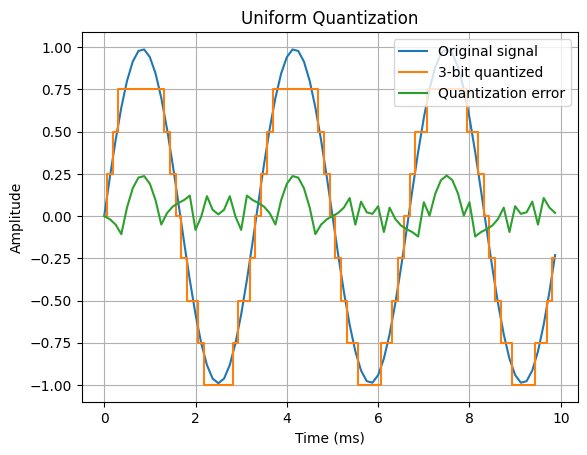

In [14]:
plt.plot(t*1e3, x, label="Original signal")
plt.step(t*1e3, xq, where="mid", label="3-bit quantized")
plt.plot(t*1e3, x - xq, label="Quantization error")

plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("Uniform Quantization")
plt.legend()
plt.grid()
plt.show()

In [15]:
bits_list = [2, 4, 6, 8, 10, 12, 14, 16]

measured_sqnr = []
theoretical_sqnr = []

for bits in bits_list:

    xq = quantize(x, bits)

    error = x - xq

    measured = 10 * np.log10(
        np.sum(x**2) / np.sum(error**2)
    )

    theoretical = 6.02 * bits + 1.76

    measured_sqnr.append(measured)
    theoretical_sqnr.append(theoretical)

print("Bits:", bits_list)
print("Measured SQNR:", measured_sqnr)
print("Theoretical SQNR:", theoretical_sqnr)

Bits: [2, 4, 6, 8, 10, 12, 14, 16]
Measured SQNR: [np.float64(9.601454182214168), np.float64(23.57671212071331), np.float64(36.81117032372333), np.float64(48.93266972314613), np.float64(62.808012346768166), np.float64(72.8359827219283), np.float64(88.13252320131404), np.float64(98.90533146415073)]
Theoretical SQNR: [13.799999999999999, 25.84, 37.879999999999995, 49.919999999999995, 61.959999999999994, 74.0, 86.04, 98.08]


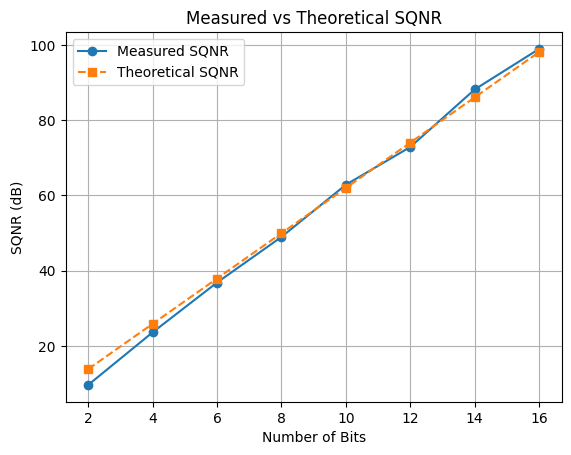

In [16]:
plt.plot(bits_list, measured_sqnr, 'o-', label="Measured SQNR")

plt.plot(bits_list, theoretical_sqnr, 's--',
         label="Theoretical SQNR")

plt.xlabel("Number of Bits")
plt.ylabel("SQNR (dB)")
plt.title("Measured vs Theoretical SQNR")

plt.legend()
plt.grid()
plt.show()

In [17]:
voice_bits = [4, 8, 12]

voice_sqnr = []

for bits in voice_bits:

    voice_q = quantize(x, bits)

    error = x - voice_q

    sqnr = 10 * np.log10(
        np.sum(x**2) / np.sum(error**2)
    )

    voice_sqnr.append(sqnr)

    print("Bits:", bits)
    print("Measured SQNR:", round(sqnr, 2), "dB")
    print("-------------------------")

Bits: 4
Measured SQNR: 23.58 dB
-------------------------
Bits: 8
Measured SQNR: 48.93 dB
-------------------------
Bits: 12
Measured SQNR: 72.84 dB
-------------------------


In [18]:
from IPython.display import Audio, display

print("Original voice:")
display(Audio(x, rate=fs_audio))

for bits in [4, 8, 12]:

    voice_q = quantize(x, bits)

    print(f"Voice quantized using {bits} bits:")
    display(Audio(voice_q, rate=fs_audio))

Original voice:


Voice quantized using 4 bits:


Voice quantized using 8 bits:


Voice quantized using 12 bits:


### Task 2.5: Voice Quantization Observations

The voice recording was quantized using 4-bit, 8-bit and 12-bit quantizers.

The 4-bit quantizer has fewer quantization levels, resulting in larger quantization errors and lower SQNR.

The 8-bit quantizer provides more quantization levels and reduces quantization noise compared to the 4-bit quantizer.

The 12-bit quantizer provides even more quantization levels, resulting in smaller quantization errors and higher SQNR.

**Why is measured speech SQNR lower than full-scale sine SQNR with the same number of bits?**

Speech signals do not continuously use the full quantization range. Their average signal power is often lower than that of a full-scale sine wave. Therefore, the measured speech SQNR is usually lower than the theoretical full-scale sine SQNR.

### Analysis Question 1

A 7 Hz sinusoidal signal sampled at 10 Hz experiences aliasing because its frequency is greater than the Nyquist frequency.

The Nyquist frequency is half the sampling frequency:

Nyquist frequency = 10/2 = 5 Hz.

Since 7 Hz is greater than 5 Hz, the signal is undersampled and appears at a different frequency.

Using the aliasing formula:

f_alias = |f0 - fs|

f_alias = |7 - 10| = 3 Hz.

Therefore, the original 7 Hz signal appears as a 3 Hz signal after sampling. This phenomenon is called aliasing.

### Analysis Question 2

Aliasing in the naive downsampling method cannot be removed afterwards because the high-frequency components have already been folded into lower frequencies during sampling.

Once aliasing occurs, the original and aliased frequency components become indistinguishable in the sampled signal.

Therefore, an anti-aliasing low-pass filter must be applied before downsampling to remove unwanted high-frequency components and prevent aliasing.

### Analysis Question 3

According to the theoretical SQNR formula:

SQNR = 6.02B + 1.76 dB

Adding one extra bit increases the SQNR by approximately 6.02 dB.

This means that increasing the quantizer resolution by one bit reduces quantization noise and improves signal quality.

The measured results should generally show an increase in SQNR as the number of bits increases. However, the measured values may differ slightly from the theoretical values because of the signal characteristics and quantization effects.

Therefore, the measurements are expected to agree with the theoretical trend of approximately 6 dB improvement per additional bit.

### Analysis Question 4

A suitable sampling rate is 1 sample per second (1 Hz), assuming that the temperature changes slowly. Since the maximum temperature change is 0.1°C per second, this sampling rate allows the system to monitor the temperature regularly. However, the exact Nyquist sampling rate cannot be determined from the rate of change alone because the highest signal frequency is not specified.

For quantization, the temperature range is from 0°C to 100°C, and the required resolution is 0.01°C.

Number of intervals = 100 / 0.01 = 10,000

Number of levels = 10,001

Number of bits = ceil(log₂(10,001)) = 14 bits.

Therefore, a minimum of 14 bits is required to represent the temperature range with a resolution of 0.01°C.

In conclusion, a sampling rate of 1 Hz and a 14-bit quantizer are suitable choices under the stated assumptions.

In [19]:
fs_voice, voice = wavfile.read("my sound.wav")

if voice.ndim == 2:
    voice = voice.mean(axis=1)

voice = voice.astype(float)
voice = voice / np.max(np.abs(voice))

print("Sampling rate:", fs_voice)
print("Voice shape:", voice.shape)
print("Maximum amplitude:", np.max(np.abs(voice)))

Sampling rate: 44100
Voice shape: (276507,)
Maximum amplitude: 1.0


In [20]:
voice_bits = [4, 8, 12]
voice_sqnr = []

for bits in voice_bits:
    voice_q = quantize(voice, bits)

    error = voice - voice_q

    sqnr = 10 * np.log10(
        np.sum(voice**2) / np.sum(error**2)
    )

    voice_sqnr.append(sqnr)

    print("Bits:", bits)
    print("Measured SQNR:", round(sqnr, 2), "dB")
    print("-------------------------")

Bits: 4
Measured SQNR: 12.0 dB
-------------------------
Bits: 8
Measured SQNR: 35.8 dB
-------------------------
Bits: 12
Measured SQNR: 59.86 dB
-------------------------


In [21]:
from IPython.display import Audio, display

print("Original voice:")
display(Audio(voice, rate=fs_voice))

for bits in [4, 8, 12]:
    voice_q = quantize(voice, bits)

    print(f"Voice quantized using {bits} bits:")
    display(Audio(voice_q, rate=fs_voice))

Original voice:


Voice quantized using 4 bits:


Voice quantized using 8 bits:


Voice quantized using 12 bits:


### Observation – Task 2.5

The original voice recording was quantized using 4-bit, 8-bit, and 12-bit resolutions.

The 4-bit quantization has fewer levels and produces larger quantization errors. The 8-bit quantization provides more levels and reduces quantization noise. The 12-bit quantization provides even more levels, resulting in smaller quantization errors and better signal quality.

The measured SQNR increases as the number of bits increases. This demonstrates that increasing the number of quantization bits improves the quality of the digital audio signal.

### AI-Use Statement

I used ChatGPT as an AI assistance tool during this laboratory exercise. It helped me understand DSP concepts such as sampling, aliasing, anti-aliasing filters, uniform quantization and SQNR.

AI assistance was also used to explain Python code, troubleshoot errors and guide the preparation of observations and analysis answers.

I executed the code in Google Colab, examined the results and used the explanations to improve my understanding of the laboratory activities.

I take responsibility for reviewing and understanding the submitted work.

### Why is the measured SQNR of speech lower than for a full-scale sine wave?

The measured SQNR of speech is usually lower than that of a full-scale sine wave because speech does not use the full quantization range continuously. Its average signal power is often lower than that of a full-scale sine wave, while quantization noise is still present. Therefore, the ratio of signal power to quantization-noise power is lower.